In [4]:
import numpy as np
import itertools
coin_space = ['H','T']
three_coin = list(itertools.product(coin_space,repeat=3))
print("Sample space:",three_coin)
three_heads =[s for s in three_coin if s.count('H')==3]
P_3H = len(three_heads)/ len(three_coin)
print(f'P(3 Heads)={P_3H}')
two_heads = [s for s in three_coin if s.count('H')==2]
P_2H = len(two_heads)/len(three_coin)
print(f'P(3 Heads)={P_2H}')
one_head = [s for s in three_coin if s.count('H')>=1]
P_1H = len(one_head)/len(three_coin)
print(f'P(at least 1 head)={P_1H}')


Sample space: [('H', 'H', 'H'), ('H', 'H', 'T'), ('H', 'T', 'H'), ('H', 'T', 'T'), ('T', 'H', 'H'), ('T', 'H', 'T'), ('T', 'T', 'H'), ('T', 'T', 'T')]
P(3 Heads)=0.125
P(3 Heads)=0.375
P(at least 1 head)=0.875


In [5]:
dice = list(range(1, 7))
A = [x for x in dice if x % 2 == 0]
B = [x for x in dice if x % 2 != 0]
B = [x for x in dice if x > 4]
P_A = len(A)/6;  P_B = len(B)/6
P_AB = len(set(A)&set(B))/6
print(f'P(A∪B) = P(A)+P(B)-P(A∩B) = {P_A+P_B-P_AB:.4f}')

P(A∪B) = P(A)+P(B)-P(A∩B) = 0.6667


In [6]:
import itertools
dice = list(range(1, 7))
two_dice=list(itertools.product(dice, dice))
sum7 = [s for s in two_dice if sum(s) == 7]
sum8 = [s for s in two_dice if sum(s) == 8]
same = [s for s in two_dice if s[0]==s[1]]
six = [s for s in two_dice if 6 in s]
Psum7 = len(sum7)/len(two_dice); Psum8 = len(sum8)/len(two_dice)  ;Psame = len(same)/len(two_dice); Psix = len(six)/len(two_dice)
print(f'P(A)= {Psum7:.4f}')
print(f'P(B)= {Psum8:.4f}')
print(f'P(C)= {Psame:.4f}')
print(f'P(D)= {Psix:.4f}')

P(A)= 0.1667
P(B)= 0.1389
P(C)= 0.1667
P(D)= 0.3056


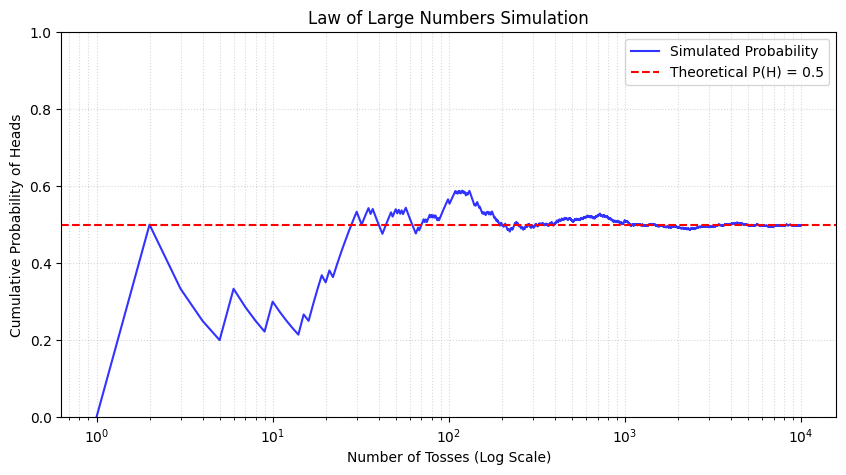

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulate 10,000 fair coin tosses (1 = Heads, 0 = Tails)
np.random.seed(42)  # For reproducible results
tosses = np.random.randint(0, 2, size=10000)

# 2. Compute cumulative metrics
n_tosses = np.arange(1, 10001)
cumulative_heads = np.cumsum(tosses)
cumulative_prob = cumulative_heads / n_tosses

# 3. Create the plot
plt.figure(figsize=(10, 5))
plt.plot(n_tosses, cumulative_prob, label="Simulated Probability", color="blue", alpha=0.8)
plt.axhline(y=0.5, color="red", linestyle="--", label="Theoretical P(H) = 0.5")

# 4. Apply logarithmic scale and formatting
plt.xscale("log")
plt.xlabel("Number of Tosses (Log Scale)")
plt.ylabel("Cumulative Probability of Heads")
plt.title("Law of Large Numbers Simulation")
plt.ylim(0, 1)
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.legend()
plt.show()

In [8]:
from fractions import Fraction

# 1. Define the sample space of a single fair die
S = {1, 2, 3, 4, 5, 6}

# 2. Define the events using set comprehensions
A = {x for x in S if x % 2 == 0}       # Even numbers
b = {x for x in S if x > 3}           # Numbers greater than 3

# 3. Find the intersection of A and B (elements in both)
A_intersect_B = A.intersection(b)

# 4. Calculate P(A|B) = n(A ∩ B) / n(B)
prob_A_given_B = Fraction(len(A_intersect_B), len(b))

# 5. Display the results
print(f"Event A (Even): {A}")
print(f"Event B (> 3): {b}")
print(f"Intersection (A ∩ B): {A_intersect_B}")
print(f"P(A|B) = {prob_A_given_B} ({float(prob_A_given_B)*100:.2f}%)")

Event A (Even): {2, 4, 6}
Event B (> 3): {4, 5, 6}
Intersection (A ∩ B): {4, 6}
P(A|B) = 2/3 (66.67%)


In [9]:
p_disease = 0.02           # Prior probability of disease: P(D)
p_no_disease = 1 - p_disease # Prior probability of no disease: P(D')

# Test characteristics
sensitivity = 0.95         # P(Pos|D): True Positive Rate
false_positive_rate = 0.04 # P(Pos|D'): False Positive Rate

# 1. Calculate total probability of testing positive: P(Pos)
# P(Pos) = [P(Pos|D) * P(D)] + [P(Pos|D') * P(D')]
p_positive = (sensitivity * p_disease) + (false_positive_rate * p_no_disease)

# 2. Apply Bayes' Theorem to find P(D|Pos)
# P(D|Pos) = [P(Pos|D) * P(D)] / P(Pos)
p_disease_given_positive = (sensitivity * p_disease) / p_positive

# 3. Output the result formatted as a percentage
print(f"Total Probability of a Positive Test: {p_positive * 100:.2f}%")
print(f"P(Disease | Positive): {p_disease_given_positive * 100:.2f}%")

Total Probability of a Positive Test: 5.82%
P(Disease | Positive): 32.65%


In [10]:
p_spam = 0.20
p_non_spam = 0.80

p_offer_given_spam = 0.80
p_offer_given_non_spam = 0.10

# Total probability of the word "offer"
p_offer = (p_offer_given_spam * p_spam) + \
          (p_offer_given_non_spam * p_non_spam)

# Bayes' theorem
p_spam_given_offer = (p_offer_given_spam * p_spam) / p_offer

print("Probability that an email contains 'offer':", p_offer)
print("Probability that the email is spam given 'offer':",
      round(p_spam_given_offer * 100, 2), "%")


Probability that an email contains 'offer': 0.24000000000000005
Probability that the email is spam given 'offer': 66.67 %


 Mean = 7.0000 (Theory: np=7.0)


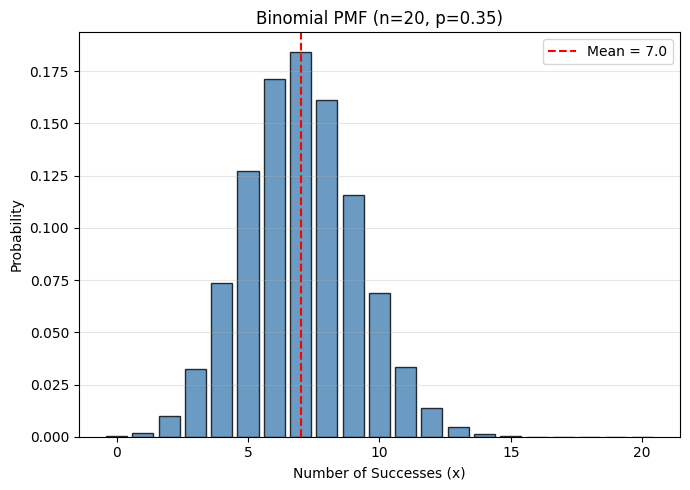

Poisson(λ=1): Th.Mean=1.0, Sim.Mean=0.976
Poisson(λ=3): Th.Mean=3.0, Sim.Mean=2.998
Poisson(λ=5): Th.Mean=5.0, Sim.Mean=5.008
Poisson(λ=10): Th.Mean=10.0, Sim.Mean=9.987


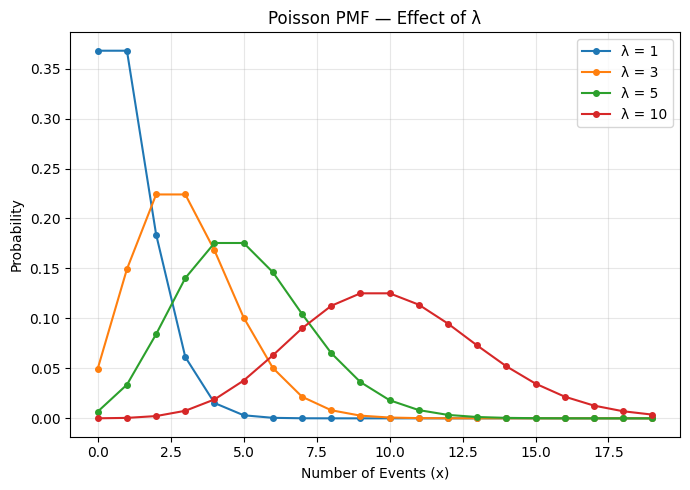

Geometric(p=0.3):
  Mean = 1/p = 3.3333
  P(X=1) = 0.3000
  P(X>5) = 0.1681


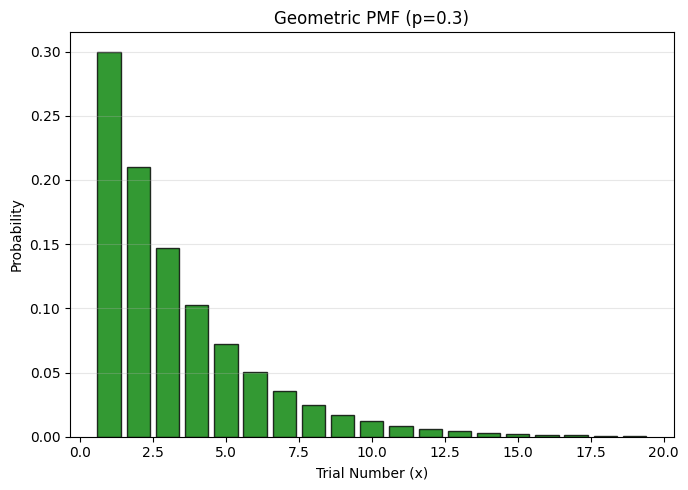

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
# Set the random seed - This makes the random simulation reproducible.
np.random.seed(42)
n, p = 20, 0.35
binom = stats.binom(n, p)
x = np.arange(0, n+1)
print(f' Mean = {binom.mean():.4f} (Theory: np={n*p})')
binom.var()
binom.moment(2)
binom.stats("s")
binom.cdf(10)
binom.pmf(7)
plt.figure(figsize=(7, 5))
plt.bar(x, binom.pmf(x), color='steelblue',
        edgecolor='black', alpha=0.8)

plt.axvline(binom.mean(), color='red', linestyle='--',
            label=f'Mean = {binom.mean():.1f}')

plt.title(f'Binomial PMF (n={n}, p={p})')
plt.xlabel('Number of Successes (x)')
plt.ylabel('Probability')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
#POISSION DISTRIBUTION
for lam in [1, 3, 5, 10]:
    d = stats.poisson(lam)
    sim = np.random.poisson(lam, 5000)
d.mean()
sim = np.random.poisson(lam, 5000)
sim.mean()
for lam in [1, 3, 5, 10]:
    d = stats.poisson(lam)
    sim = np.random.poisson(lam, 5000)
    print(f'Poisson(λ={lam}): Th.Mean={d.mean()}, Sim.Mean={sim.mean():.3f}')
plt.figure(figsize=(7, 5))

x_p = np.arange(0, 20)

for lam in [1, 3, 5, 10]:
    plt.plot(x_p, stats.poisson.pmf(x_p, lam),
             marker='o', markersize=4, label=f'λ = {lam}')

plt.title('Poisson PMF — Effect of λ')
plt.xlabel('Number of Events (x)')
plt.ylabel('Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
#GE0METRIC DISTRIBUTION
p_geo = 0.3
geo = stats.geom(p_geo)
geo.mean()
geo.pmf(1)
1 - geo.cdf(5)
print(f'Geometric(p={p_geo}):')
print(f'  Mean = 1/p = {geo.mean():.4f}')
print(f'  P(X=1) = {geo.pmf(1):.4f}')
print(f'  P(X>5) = {1 - geo.cdf(5):.4f}')
plt.figure(figsize=(7, 5))

x_g = np.arange(1, 20)

plt.bar(x_g, geo.pmf(x_g), color='green',
        edgecolor='black', alpha=0.8)

plt.title(f'Geometric PMF (p={p_geo})')
plt.xlabel('Trial Number (x)')
plt.ylabel('Probability')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

program 2:binomial implimentation